Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Logistic Regression
              precision    recall  f1-score   support

    Consumer       0.52      0.99      0.68        82
   Corporate       0.00      0.00      0.00        47
 Home Office       0.00      0.00      0.00        30

    accuracy                           0.51       159
   macro avg       0.17      0.33      0.23       159
weighted avg       0.27      0.51      0.35       159


SVM
              precision    recall  f1-score   support

    Consumer       0.52      0.95      0.68        82
   Corporate       0.30      0.06      0.11        47
 Home Office       0.00      0.00      0.00        30

    accuracy                           0.51       159
   macro avg       0.27      0.34      0.26       159
weighted avg       0.36      0.51      0.38       159


Decision Tree
              precision    recall  f1-score   support

    Consumer 

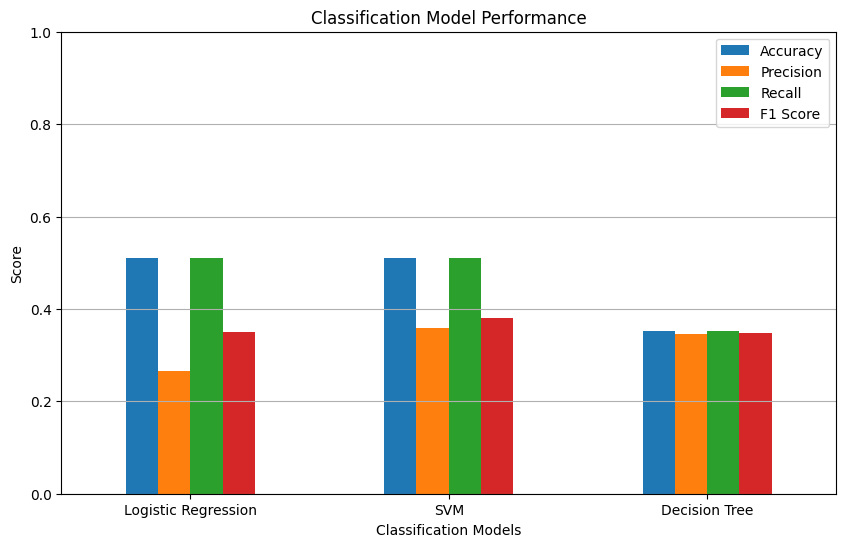

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Load dataset
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/PBA PRACTICAL FILE/superstore.csv'
)

# Create customer-level data
customer_df = df.groupby('Customer ID').agg({
    'Sales': ['sum', 'mean'],
    'Order ID': 'nunique',
    'Product ID': 'nunique',
    'Segment': 'first',
    'Region': 'first'
}).reset_index()

# Rename columns
customer_df.columns = [
    'Customer_ID',
    'Total_Sales',
    'Average_Sales',
    'Number_of_Orders',
    'Number_of_Products',
    'Segment',
    'Region'
]

# Convert Region into numbers
region_encoder = LabelEncoder()

customer_df['Region'] = region_encoder.fit_transform(
    customer_df['Region']
)

# Features and target
X = customer_df[
    [
        'Total_Sales',
        'Average_Sales',
        'Number_of_Orders',
        'Number_of_Products',
        'Region'
    ]
]

# Convert target into numbers
target_encoder = LabelEncoder()

y = target_encoder.fit_transform(
    customer_df['Segment']
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Classification models
models = {
    'Logistic Regression': LogisticRegression(),
    'SVM': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

# Store results
results = []

# Train and evaluate
for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Classification report
    report = classification_report(
        y_test,
        y_pred,
        target_names=target_encoder.classes_,
        output_dict=True,
        zero_division=0)

    # Display report
    print('\n' + '=' * 50)
    print(name)
    print('=' * 50)
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=target_encoder.classes_,
            zero_division=0
        )
    )

    # Store weighted average values
    results.append([
        name,
        report['accuracy'],
        report['weighted avg']['precision'],
        report['weighted avg']['recall'],
        report['weighted avg']['f1-score']
    ])

# Create results table
results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'])

print('\nModel Comparison:')
print(results_df)


# Bar graph
import matplotlib.pyplot as plt
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6))

plt.title('Classification Model Performance')
plt.xlabel('Classification Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()
